In [1]:

import sys
import gc
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from scipy.stats import rankdata
from torch.utils.data import DataLoader
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0,str(ROOT_DIR))
from rating_dataset import RatingDataset
from model import SparseLandauScoreField
from others import create_baseline
RAW_TEST_DIR=ROOT_DIR/'data'/'test_data'
TEST_DIR=ROOT_DIR/'data'/'test_face_data'
TEST_MASK_DIR=ROOT_DIR/'data'/'test_face_masks'
TRAIN_DIR=ROOT_DIR/'data'/'face_data'
WEIGHTS_DIR=ROOT_DIR/'weights'
TABLE_DIR=ROOT_DIR/'outputs'/'tables'
TABLE_FILE=TABLE_DIR/'main_comparison.csv'
TRAIN_LOG=ROOT_DIR/'outputs'/'recent_compare'/'seed_best_metrics.csv'
METHODS=['ours','EUPE','TIPSV2','QWEN35','MOBILECLIP2','PECORE','IFORMER']
SEEDS=[42,123,2026,3407,777]
METRICS=['emd','mae','nll','spearman']
TEST_IMAGE_SIZE=336
IMAGE_BATCH_SIZE=4
HEAD_BATCH_SIZE=128
NUM_WORKERS=0
BOOTSTRAP_REPEATS=2000
PERMUTATION_REPEATS=3000
CONFIDENCE_LEVEL=0.95
ALPHA=0.05
RESAMPLE_SEED=20261101
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP=DEVICE.type=='cuda'
from utils import preprocess_face_dataset
if not RAW_TEST_DIR.is_dir():
    raise FileNotFoundError(f'原始测试集目录不存在: {RAW_TEST_DIR}')
raw_test_images=sorted(path for path in RAW_TEST_DIR.iterdir() if path.suffix.lower() in {'.jpg','.jpeg','.png'})
if not raw_test_images:
    raise RuntimeError('原始测试集没有找到照片')
missing_txt=[str(path.with_suffix('.txt')) for path in raw_test_images if not path.with_suffix('.txt').is_file()]
if missing_txt:
    raise FileNotFoundError(f'以下测试照片缺少评分TXT文件: {missing_txt[:10]}')
missing_preprocessed=[path for path in raw_test_images if not (TEST_DIR/path.name).is_file() or not (TEST_MASK_DIR/f'{path.stem}.png').is_file() or not (TEST_DIR/f'{path.stem}.txt').is_file()]
if missing_preprocessed:
    print(f'需要预处理的测试照片: {len(missing_preprocessed)}')
    preprocess_face_dataset(src_dir=str(RAW_TEST_DIR),dst_dir=str(TEST_DIR),mask_dir=str(TEST_MASK_DIR),size=448,expand=1.75)
else:
    print('测试照片已完成预处理，跳过重复处理')
print(f'测试集裁剪目录: {TEST_DIR}')

if not TEST_DIR.is_dir():
    raise FileNotFoundError(f'测试目录不存在: {TEST_DIR}')
if len(SEEDS)!=len(set(SEEDS)) or len(SEEDS)<2:
    raise ValueError('SEEDS必须包含至少两个不同的独立训练种子')
if not 0.0<CONFIDENCE_LEVEL<1.0 or not 0.0<ALPHA<1.0:
    raise ValueError('置信度与显著性阈值必须在(0,1)之间')
checkpoint_paths={(method,seed):WEIGHTS_DIR/f'{method}_{seed}.pt' for method in METHODS for seed in SEEDS}
missing_paths=[str(path) for path in checkpoint_paths.values() if not path.is_file()]
if missing_paths:
    raise FileNotFoundError('以下多种子权重不存在:\n'+'\n'.join(missing_paths))
if not TRAIN_LOG.is_file():
    raise FileNotFoundError(f'多种子训练记录不存在: {TRAIN_LOG}')
seed_log=pd.read_csv(TRAIN_LOG)
required_log_columns={'method','seed','best_epoch','checkpoint'}
if not required_log_columns.issubset(seed_log.columns):
    raise RuntimeError(f'多种子训练记录缺少列: {sorted(required_log_columns-set(seed_log.columns))}')
seed_log['method']=seed_log['method'].astype(str)
seed_log['seed']=pd.to_numeric(seed_log['seed'],errors='raise').astype(int)
for method in METHODS:
    for seed in SEEDS:
        matched=seed_log.loc[(seed_log['method']==method)&(seed_log['seed']==seed)]
        if len(matched)!=1 or str(matched.iloc[0]['checkpoint'])!=checkpoint_paths[(method,seed)].name:
            raise RuntimeError(f'多种子训练记录与权重不一致: {method}_{seed}.pt')
USE_TEST_MASK=(ROOT_DIR/'data'/'face_masks').is_dir()
test_dataset=RatingDataset(str(TEST_DIR),mask_dir=str(TEST_MASK_DIR) if USE_TEST_MASK else None,augment=False,repeat=1,image_size=TEST_IMAGE_SIZE,soft_target=False)
test_loader=DataLoader(test_dataset,batch_size=IMAGE_BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
TEST_NAMES=[path.name for path in test_dataset.image_paths]
if len(TEST_NAMES)<20:
    raise RuntimeError('测试照片不足20张，当前置信区间与Spearman检验可能不可靠')
if TRAIN_DIR.is_dir():
    training_names={path.name.casefold() for path in TRAIN_DIR.iterdir() if path.suffix.lower() in {'.jpg','.jpeg','.png'}}
    overlaps=sorted(set(name.casefold() for name in TEST_NAMES)&training_names)
    if overlaps:
        raise RuntimeError(f'测试集与训练/验证目录出现同名照片: {overlaps[:10]}')
TEST_RATING_COUNTS=np.asarray([len(test_dataset._read_scores(path.with_suffix('.txt'))) for path in test_dataset.image_paths],dtype=np.int32)
print(f'设备: {DEVICE} | 测试照片: {len(TEST_NAMES)} | 单评分照片: {int((TEST_RATING_COUNTS==1).sum())}')
print(f'待评估模型: {len(METHODS)} | 独立训练种子: {len(SEEDS)} | 完整权重: {len(checkpoint_paths)}')
print('本Notebook仅评估已训练权重；不训练、不调参、不创建额外输出文件')


需要预处理的测试照片: 1480


D:\miniconda\envs\myenv\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\miniconda\envs\myenv\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


需要人工检查：2636.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2649.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2722.jpg，检测到 0 张脸，暂时保留整图
需要人工检查：2743.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2797.jpg，检测到 0 张脸，暂时保留整图
需要人工检查：2859.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2871.jpg，检测到 0 张脸，暂时保留整图
需要人工检查：2872.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2873.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2891.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2895.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2950.jpg，检测到 3 张脸，暂时保留整图
需要人工检查：2951.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：2990.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3006.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3022.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3046.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3057.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3092.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3119.jpg，检测到 6 张脸，暂时保留整图
需要人工检查：3120.jpg，检测到 7 张脸，暂时保留整图
需要人工检查：3135.jpg，检测到 4 张脸，暂时保留整图
需要人工检查：3149.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3164.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3183.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3195.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3201.jpg，检测到 3 张脸，暂时保留整图
需要人工检查：3221.jpg，检测到 3 张脸，暂时保留整图
需要人工检查：3230.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3236.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3237.jpg，检测到 2 张脸，暂时保留整图
需要人工检查：3

In [2]:

class FrozenEncoderTokenAdapter(torch.nn.Module):
    def __init__(self,encoder,input_size,mean,std):
        super().__init__()
        self.encoder=encoder
        self.embed_dim=int(encoder.num_features)
        self.global_only=True
        self.input_size=int(input_size)
        self.register_buffer('mean',mean.detach().clone())
        self.register_buffer('std',std.detach().clone())
    def get_intermediate_layers(self,x,n=3,return_class_token=True,norm=True):
        features=self.encoder(x)
        tokens=features.unsqueeze(1)
        return [(tokens,features) for _ in range(3)]
    def train(self,mode=True):
        super().train(mode)
        self.encoder.eval()
        return self
def build_evaluation_model(method):
    if method!='ours':
        return create_baseline(method,pretrained=False,freeze_backbone=True,dropout=0.10)
    tip_model=create_baseline('TIPSV2',pretrained=False,freeze_backbone=True,dropout=0.0)
    tip_adapter=FrozenEncoderTokenAdapter(tip_model.backbone,tip_model.input_size,tip_model.mean,tip_model.std)
    net=SparseLandauScoreField(pretrained=False,backbone=tip_adapter,dropout=0.10,train_last_stage=False,width=24,prior_mix=0.0,use_entropy=False,use_high_resolution=False,scales=(224,),grid_side=16,use_evidence_head=True,evidence_base=0.1,use_global_token=True)
    with torch.no_grad():
        net.mean.copy_(tip_adapter.mean)
        net.std.copy_(tip_adapter.std)
    del tip_model
    return net
def read_checkpoint(path):
    state=torch.load(path,map_location='cpu',weights_only=True)
    if not isinstance(state,dict) or not all(isinstance(value,torch.Tensor) for value in state.values()):
        raise RuntimeError(f'权重必须为直接保存的state_dict: {path}')
    return state
def verify_frozen_backbone(reference_state,current_state,method,seed):
    for name,reference in reference_state.items():
        if name.startswith('backbone.') or name in ('mean','std'):
            if name not in current_state or not torch.equal(reference,current_state[name]):
                raise RuntimeError(f'{method}种子{seed}的冻结编码器或归一化参数发生变化，不允许共享视觉特征: {name}')
@torch.inference_mode()
def extract_test_features(net,method):
    net.eval()
    feature_parts=[]
    label_parts=[]
    for inputs,targets in test_loader:
        inputs=inputs.to(DEVICE,non_blocking=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP):
            features=net.encode_features(inputs) if method=='ours' else net.extract_features(inputs)
        feature_parts.append(features.float().cpu())
        label_parts.append(targets.float().cpu())
    return torch.cat(feature_parts,dim=0),torch.cat(label_parts,dim=0).numpy().astype(np.float64)
@torch.inference_mode()
def predict_from_cached_features(net,method,features):
    net.eval()
    parts=[]
    for start in range(0,len(features),HEAD_BATCH_SIZE):
        batch=features[start:start+HEAD_BATCH_SIZE].to(DEVICE,non_blocking=True)
        if method=='ours':
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP):
                log_probs=net(batch)
        else:
            log_probs=net.forward_from_features(batch)
        if log_probs.shape!=(len(batch),10):
            raise RuntimeError(f'{method}的预测维度不符合[B,10]: {tuple(log_probs.shape)}')
        parts.append(log_probs.float().exp().cpu().numpy().astype(np.float64))
    probabilities=np.concatenate(parts,axis=0)
    if not np.isfinite(probabilities).all() or (probabilities<0.0).any():
        raise RuntimeError(f'{method}的概率存在非法值')
    return probabilities/probabilities.sum(axis=1,keepdims=True)
all_predictions={}
test_targets=None
for method in METHODS:
    print(f'开始评估 {method}',flush=True)
    net=build_evaluation_model(method)
    reference_state=read_checkpoint(checkpoint_paths[(method,SEEDS[0])])
    net.load_state_dict(reference_state,strict=True)
    net=net.to(DEVICE).eval()
    features,labels=extract_test_features(net,method)
    if test_targets is None:
        test_targets=labels
    elif not np.array_equal(test_targets,labels):
        raise RuntimeError(f'{method}加载的测试集标签与其他方法不一致')
    predictions_for_seeds=[]
    for seed in SEEDS:
        state=reference_state if seed==SEEDS[0] else read_checkpoint(checkpoint_paths[(method,seed)])
        if seed!=SEEDS[0]:
            verify_frozen_backbone(reference_state,state,method,seed)
            net.load_state_dict(state,strict=True)
        predictions_for_seeds.append(predict_from_cached_features(net,method,features))
        print(f'  已完成: {checkpoint_paths[(method,seed)].name}',flush=True)
        if seed!=SEEDS[0]:
            del state
    all_predictions[method]=np.stack(predictions_for_seeds,axis=0)
    del net,reference_state,features,labels,predictions_for_seeds
    gc.collect()
    if USE_AMP:
        torch.cuda.empty_cache()
if test_targets.shape!=(len(TEST_NAMES),10) or not np.isfinite(test_targets).all() or (test_targets<0).any() or not np.allclose(test_targets.sum(axis=1),1.0,atol=1e-6):
    raise RuntimeError('测试标签不是合法的10维经验概率分布')
print('全部35个训练权重已完成测试推理，未使用测试集进行训练或权重选择')


开始评估 ours
  已完成: ours_42.pt
  已完成: ours_123.pt
  已完成: ours_2026.pt
  已完成: ours_3407.pt
  已完成: ours_777.pt
开始评估 EUPE
  已完成: EUPE_42.pt
  已完成: EUPE_123.pt
  已完成: EUPE_2026.pt
  已完成: EUPE_3407.pt
  已完成: EUPE_777.pt
开始评估 TIPSV2
  已完成: TIPSV2_42.pt
  已完成: TIPSV2_123.pt
  已完成: TIPSV2_2026.pt
  已完成: TIPSV2_3407.pt
  已完成: TIPSV2_777.pt
开始评估 QWEN35
  已完成: QWEN35_42.pt
  已完成: QWEN35_123.pt
  已完成: QWEN35_2026.pt
  已完成: QWEN35_3407.pt
  已完成: QWEN35_777.pt
开始评估 MOBILECLIP2
  已完成: MOBILECLIP2_42.pt
  已完成: MOBILECLIP2_123.pt
  已完成: MOBILECLIP2_2026.pt
  已完成: MOBILECLIP2_3407.pt
  已完成: MOBILECLIP2_777.pt
开始评估 PECORE
  已完成: PECORE_42.pt
  已完成: PECORE_123.pt
  已完成: PECORE_2026.pt
  已完成: PECORE_3407.pt
  已完成: PECORE_777.pt
开始评估 IFORMER
  已完成: IFORMER_42.pt
  已完成: IFORMER_123.pt
  已完成: IFORMER_2026.pt
  已完成: IFORMER_3407.pt
  已完成: IFORMER_777.pt
全部35个训练权重已完成测试推理，未使用测试集进行训练或权重选择


In [3]:

def spearman_rows(x,y):
    x=np.asarray(x,dtype=np.float64)
    if x.ndim==1:
        x=x[None,:]
    rx=rankdata(x,axis=1)
    ry=rankdata(np.asarray(y,dtype=np.float64))
    rx=rx-rx.mean(axis=1,keepdims=True)
    ry=ry-ry.mean()
    denom=np.linalg.norm(rx,axis=1)*np.linalg.norm(ry)
    result=np.divide((rx*ry[None,:]).sum(axis=1),denom,out=np.full(x.shape[0],np.nan),where=denom>1e-12)
    return result
bins=np.arange(1,11,dtype=np.float64)
target_means=test_targets@bins
if np.unique(target_means).size<2:
    raise RuntimeError('测试评分均值没有变化，无法计算Spearman')
method_stats={}
for method in METHODS:
    probs=all_predictions[method]
    if probs.shape!=(len(SEEDS),len(TEST_NAMES),10):
        raise RuntimeError(f'{method}预测形状不正确: {probs.shape}')
    cdf_delta=np.cumsum(probs,axis=2)-np.cumsum(test_targets[None,:,:],axis=2)
    emd=np.sqrt(np.square(cdf_delta).mean(axis=2))
    mean_pred=probs@bins
    mae=np.abs(mean_pred-target_means[None,:])
    nll=-(test_targets[None,:,:]*np.log(np.maximum(probs,1e-12))).sum(axis=2)
    per_photo=np.stack([emd,mae,nll],axis=2)
    correlations=spearman_rows(mean_pred,target_means)
    seed_metrics=np.concatenate([per_photo.mean(axis=1),correlations[:,None]],axis=1)
    if not np.isfinite(seed_metrics).all():
        raise RuntimeError(f'{method}有非有限指标，请检查模型预测与评分标签')
    method_stats[method]={'per_photo':per_photo,'pred_mean':mean_pred,'seed_metrics':seed_metrics,'mean':seed_metrics.mean(axis=0),'seed_sd':seed_metrics.std(axis=0,ddof=1)}
    print(f'{method:12s} EMD={seed_metrics[:,0].mean():.5f}±{seed_metrics[:,0].std(ddof=1):.5f} MAE={seed_metrics[:,1].mean():.5f} NLL={seed_metrics[:,2].mean():.5f} Spearman={seed_metrics[:,3].mean():.5f}')
def subset_metric(info,photo_ids,seed_ids):
    losses=info['per_photo'][seed_ids][:,photo_ids,:].mean(axis=(0,1))
    rho=spearman_rows(info['pred_mean'][seed_ids][:,photo_ids],target_means[photo_ids]).mean()
    return np.concatenate([losses,np.asarray([rho])])
rng=np.random.default_rng(RESAMPLE_SEED)
boot_stats=np.empty((BOOTSTRAP_REPEATS,len(METHODS),len(METRICS)),dtype=np.float64)
for iteration in range(BOOTSTRAP_REPEATS):
    photo_ids=rng.integers(0,len(TEST_NAMES),size=len(TEST_NAMES))
    seed_ids=rng.integers(0,len(SEEDS),size=len(SEEDS))
    for index,method in enumerate(METHODS):
        boot_stats[iteration,index]=subset_metric(method_stats[method],photo_ids,seed_ids)
valid_boot=np.isfinite(boot_stats).all(axis=(1,2))
boot_stats=boot_stats[valid_boot]
if len(boot_stats)<BOOTSTRAP_REPEATS*0.9:
    raise RuntimeError('有效Bootstrap次数不足90%，请检查测试集评分均值分布是否过于单一')
print(f'分层配对Bootstrap完成: {len(boot_stats)}次 | 共同重采样测试照片和训练种子 | 置信度{CONFIDENCE_LEVEL:.0%}')


ours         EMD=0.22043±0.00600 MAE=1.04521 NLL=1.78549 Spearman=0.64414
EUPE         EMD=0.22398±0.00083 MAE=1.09541 NLL=1.79159 Spearman=0.55609
TIPSV2       EMD=0.22606±0.00055 MAE=1.09843 NLL=1.80494 Spearman=0.54902
QWEN35       EMD=0.24982±0.00196 MAE=1.30209 NLL=1.98510 Spearman=0.45914
MOBILECLIP2  EMD=0.23474±0.00067 MAE=1.17568 NLL=1.83761 Spearman=0.45585
PECORE       EMD=0.22295±0.00055 MAE=1.07373 NLL=1.78572 Spearman=0.54193
IFORMER      EMD=0.24606±0.00448 MAE=1.24935 NLL=1.97575 Spearman=0.34046
分层配对Bootstrap完成: 2000次 | 共同重采样测试照片和训练种子 | 置信度95%


In [4]:

def image_paired_permutation(other):
    ours=method_stats['ours']
    baseline=method_stats[other]
    image_advantage=baseline['per_photo'].mean(axis=0)-ours['per_photo'].mean(axis=0)
    observed=np.concatenate([image_advantage.mean(axis=0),np.asarray([ours['mean'][3]-baseline['mean'][3]])])
    exceed=np.zeros(len(METRICS),dtype=np.int64)
    rng=np.random.default_rng(RESAMPLE_SEED+1009+METHODS.index(other))
    for iteration in range(PERMUTATION_REPEATS):
        switched=rng.integers(0,2,size=len(TEST_NAMES)).astype(bool)
        signed=np.where(switched,-1.0,1.0)
        null_additive=(image_advantage*signed[:,None]).mean(axis=0)
        switched_ours=np.where(switched[None,:],baseline['pred_mean'],ours['pred_mean'])
        switched_other=np.where(switched[None,:],ours['pred_mean'],baseline['pred_mean'])
        null_rho=spearman_rows(switched_ours,target_means).mean()-spearman_rows(switched_other,target_means).mean()
        null=np.concatenate([null_additive,np.asarray([null_rho])])
        exceed+=(np.abs(null)>=np.abs(observed)-1e-12)
    return (exceed+1.0)/(PERMUTATION_REPEATS+1.0)
def seed_exact_signflip_p(other):
    ours=method_stats['ours']['seed_metrics']
    baseline=method_stats[other]['seed_metrics']
    differences=np.concatenate([baseline[:,:3]-ours[:,:3],ours[:,3:]-baseline[:,3:]],axis=1)
    signs=np.asarray(list(product([-1.0,1.0],repeat=len(SEEDS))),dtype=np.float64)
    null_means=(signs[:,:,None]*differences[None,:,:]).mean(axis=1)
    observed=differences.mean(axis=0)
    return (np.abs(null_means)>=np.abs(observed[None,:])-1e-12).mean(axis=0)
def holm_adjust(p_values):
    p_values=np.asarray(p_values,dtype=np.float64)
    order=np.argsort(p_values)
    adjusted=np.maximum.accumulate(p_values[order]*(len(p_values)-np.arange(len(p_values))))
    result=np.empty_like(adjusted)
    result[order]=np.minimum(adjusted,1.0)
    return result
baseline_methods=[method for method in METHODS if method!='ours']
image_p_raw={method:image_paired_permutation(method) for method in baseline_methods}
seed_p_raw={method:seed_exact_signflip_p(method) for method in baseline_methods}
image_adjusted=holm_adjust(np.concatenate([image_p_raw[method] for method in baseline_methods]))
seed_adjusted=holm_adjust(np.concatenate([seed_p_raw[method] for method in baseline_methods]))
image_p_holm={method:image_adjusted[i*4:(i+1)*4] for i,method in enumerate(baseline_methods)}
seed_p_holm={method:seed_adjusted[i*4:(i+1)*4] for i,method in enumerate(baseline_methods)}
print('检验完成: 每种方法与ours的4个指标，共24次比较，已分别进行Holm校正')
print('图片级置换检验在固定5个训练权重条件下进行；训练种子精确符号检验仅有5对种子，统计功效较低')


检验完成: 每种方法与ours的4个指标，共24次比较，已分别进行Holm校正
图片级置换检验在固定5个训练权重条件下进行；训练种子精确符号检验仅有5对种子，统计功效较低


In [5]:

ci_alpha=(1.0-CONFIDENCE_LEVEL)/2.0
rows=[]
for index,method in enumerate(METHODS):
    info=method_stats[method]
    row={'model':method,'test_photos':len(TEST_NAMES),'single_rating_photos':int((TEST_RATING_COUNTS==1).sum()),'train_seed_count':len(SEEDS),'train_seeds':','.join(str(seed) for seed in SEEDS),'checkpoints':'|'.join(checkpoint_paths[(method,seed)].name for seed in SEEDS),'bootstrap_iterations':len(boot_stats),'permutation_iterations':PERMUTATION_REPEATS,'confidence_level':CONFIDENCE_LEVEL,'alpha':ALPHA,'p_adjustment':'Holm_24_comparisons'}
    train_record=seed_log.loc[(seed_log['method']==method)&seed_log['seed'].isin(SEEDS)].set_index('seed').loc[SEEDS]
    row['best_epoch_mean']=float(train_record['best_epoch'].mean())
    row['best_epoch_sd']=float(train_record['best_epoch'].std(ddof=1))
    for k,metric in enumerate(METRICS):
        row[f'{metric}_mean']=float(info['mean'][k])
        row[f'{metric}_seed_sd']=float(info['seed_sd'][k])
        row[f'{metric}_ci_low']=float(np.quantile(boot_stats[:,index,k],ci_alpha))
        row[f'{metric}_ci_high']=float(np.quantile(boot_stats[:,index,k],1.0-ci_alpha))
        if method=='ours':
            row[f'{metric}_ours_advantage']=np.nan
            row[f'{metric}_advantage_ci_low']=np.nan
            row[f'{metric}_advantage_ci_high']=np.nan
            row[f'{metric}_p_image_raw']=np.nan
            row[f'{metric}_p_image_holm']=np.nan
            row[f'{metric}_p_seed_raw']=np.nan
            row[f'{metric}_p_seed_holm']=np.nan
            row[f'{metric}_ours_better_seed_count']=np.nan
            row[f'{metric}_ours_better_significant']=np.nan
        else:
            sign=1.0 if metric=='spearman' else -1.0
            advantage=sign*(method_stats['ours']['mean'][k]-info['mean'][k])
            advantage_boot=sign*(boot_stats[:,0,k]-boot_stats[:,index,k])
            seed_advantage=sign*(method_stats['ours']['seed_metrics'][:,k]-info['seed_metrics'][:,k])
            row[f'{metric}_ours_advantage']=float(advantage)
            row[f'{metric}_advantage_ci_low']=float(np.quantile(advantage_boot,ci_alpha))
            row[f'{metric}_advantage_ci_high']=float(np.quantile(advantage_boot,1.0-ci_alpha))
            row[f'{metric}_p_image_raw']=float(image_p_raw[method][k])
            row[f'{metric}_p_image_holm']=float(image_p_holm[method][k])
            row[f'{metric}_p_seed_raw']=float(seed_p_raw[method][k])
            row[f'{metric}_p_seed_holm']=float(seed_p_holm[method][k])
            row[f'{metric}_ours_better_seed_count']=int((seed_advantage>0.0).sum())
            row[f'{metric}_ours_better_significant']=bool(advantage>0.0 and image_p_holm[method][k]<ALPHA)
    rows.append(row)
main_table=pd.DataFrame.from_records(rows)
TABLE_DIR.mkdir(parents=True,exist_ok=True)
main_table.to_csv(TABLE_FILE,index=False,encoding='utf-8-sig',float_format='%.8f')
print(main_table[['model','emd_mean','emd_seed_sd','mae_mean','nll_mean','spearman_mean']].to_string(index=False,float_format=lambda value:f'{value:.5f}'))
print(f'已保存唯一主对比表格: {TABLE_FILE}')
print('说明: 指标mean为5个独立训练种子的算术均值；seed_sd为种子间样本标准差')
print('CI为同时对测试照片与配对训练种子重采样的百分位Bootstrap区间')
print('p_image为给定5组权重条件下的照片级配对置换检验；p_seed为5对训练种子的精确符号检验')
print('EMD/MAE/NLL越小越好，Spearman越大越好；ours_advantage>0表示ours占优')


      model  emd_mean  emd_seed_sd  mae_mean  nll_mean  spearman_mean
       ours   0.22043      0.00600   1.04521   1.78549        0.64414
       EUPE   0.22398      0.00083   1.09541   1.79159        0.55609
     TIPSV2   0.22606      0.00055   1.09843   1.80494        0.54902
     QWEN35   0.24982      0.00196   1.30209   1.98510        0.45914
MOBILECLIP2   0.23474      0.00067   1.17568   1.83761        0.45585
     PECORE   0.22295      0.00055   1.07373   1.78572        0.54193
    IFORMER   0.24606      0.00448   1.24935   1.97575        0.34046
已保存唯一主对比表格: D:\MyJupyter\Works\FaceScore\outputs\tables\main_comparison.csv
说明: 指标mean为5个独立训练种子的算术均值；seed_sd为种子间样本标准差
CI为同时对测试照片与配对训练种子重采样的百分位Bootstrap区间
p_image为给定5组权重条件下的照片级配对置换检验；p_seed为5对训练种子的精确符号检验
EMD/MAE/NLL越小越好，Spearman越大越好；ours_advantage>0表示ours占优


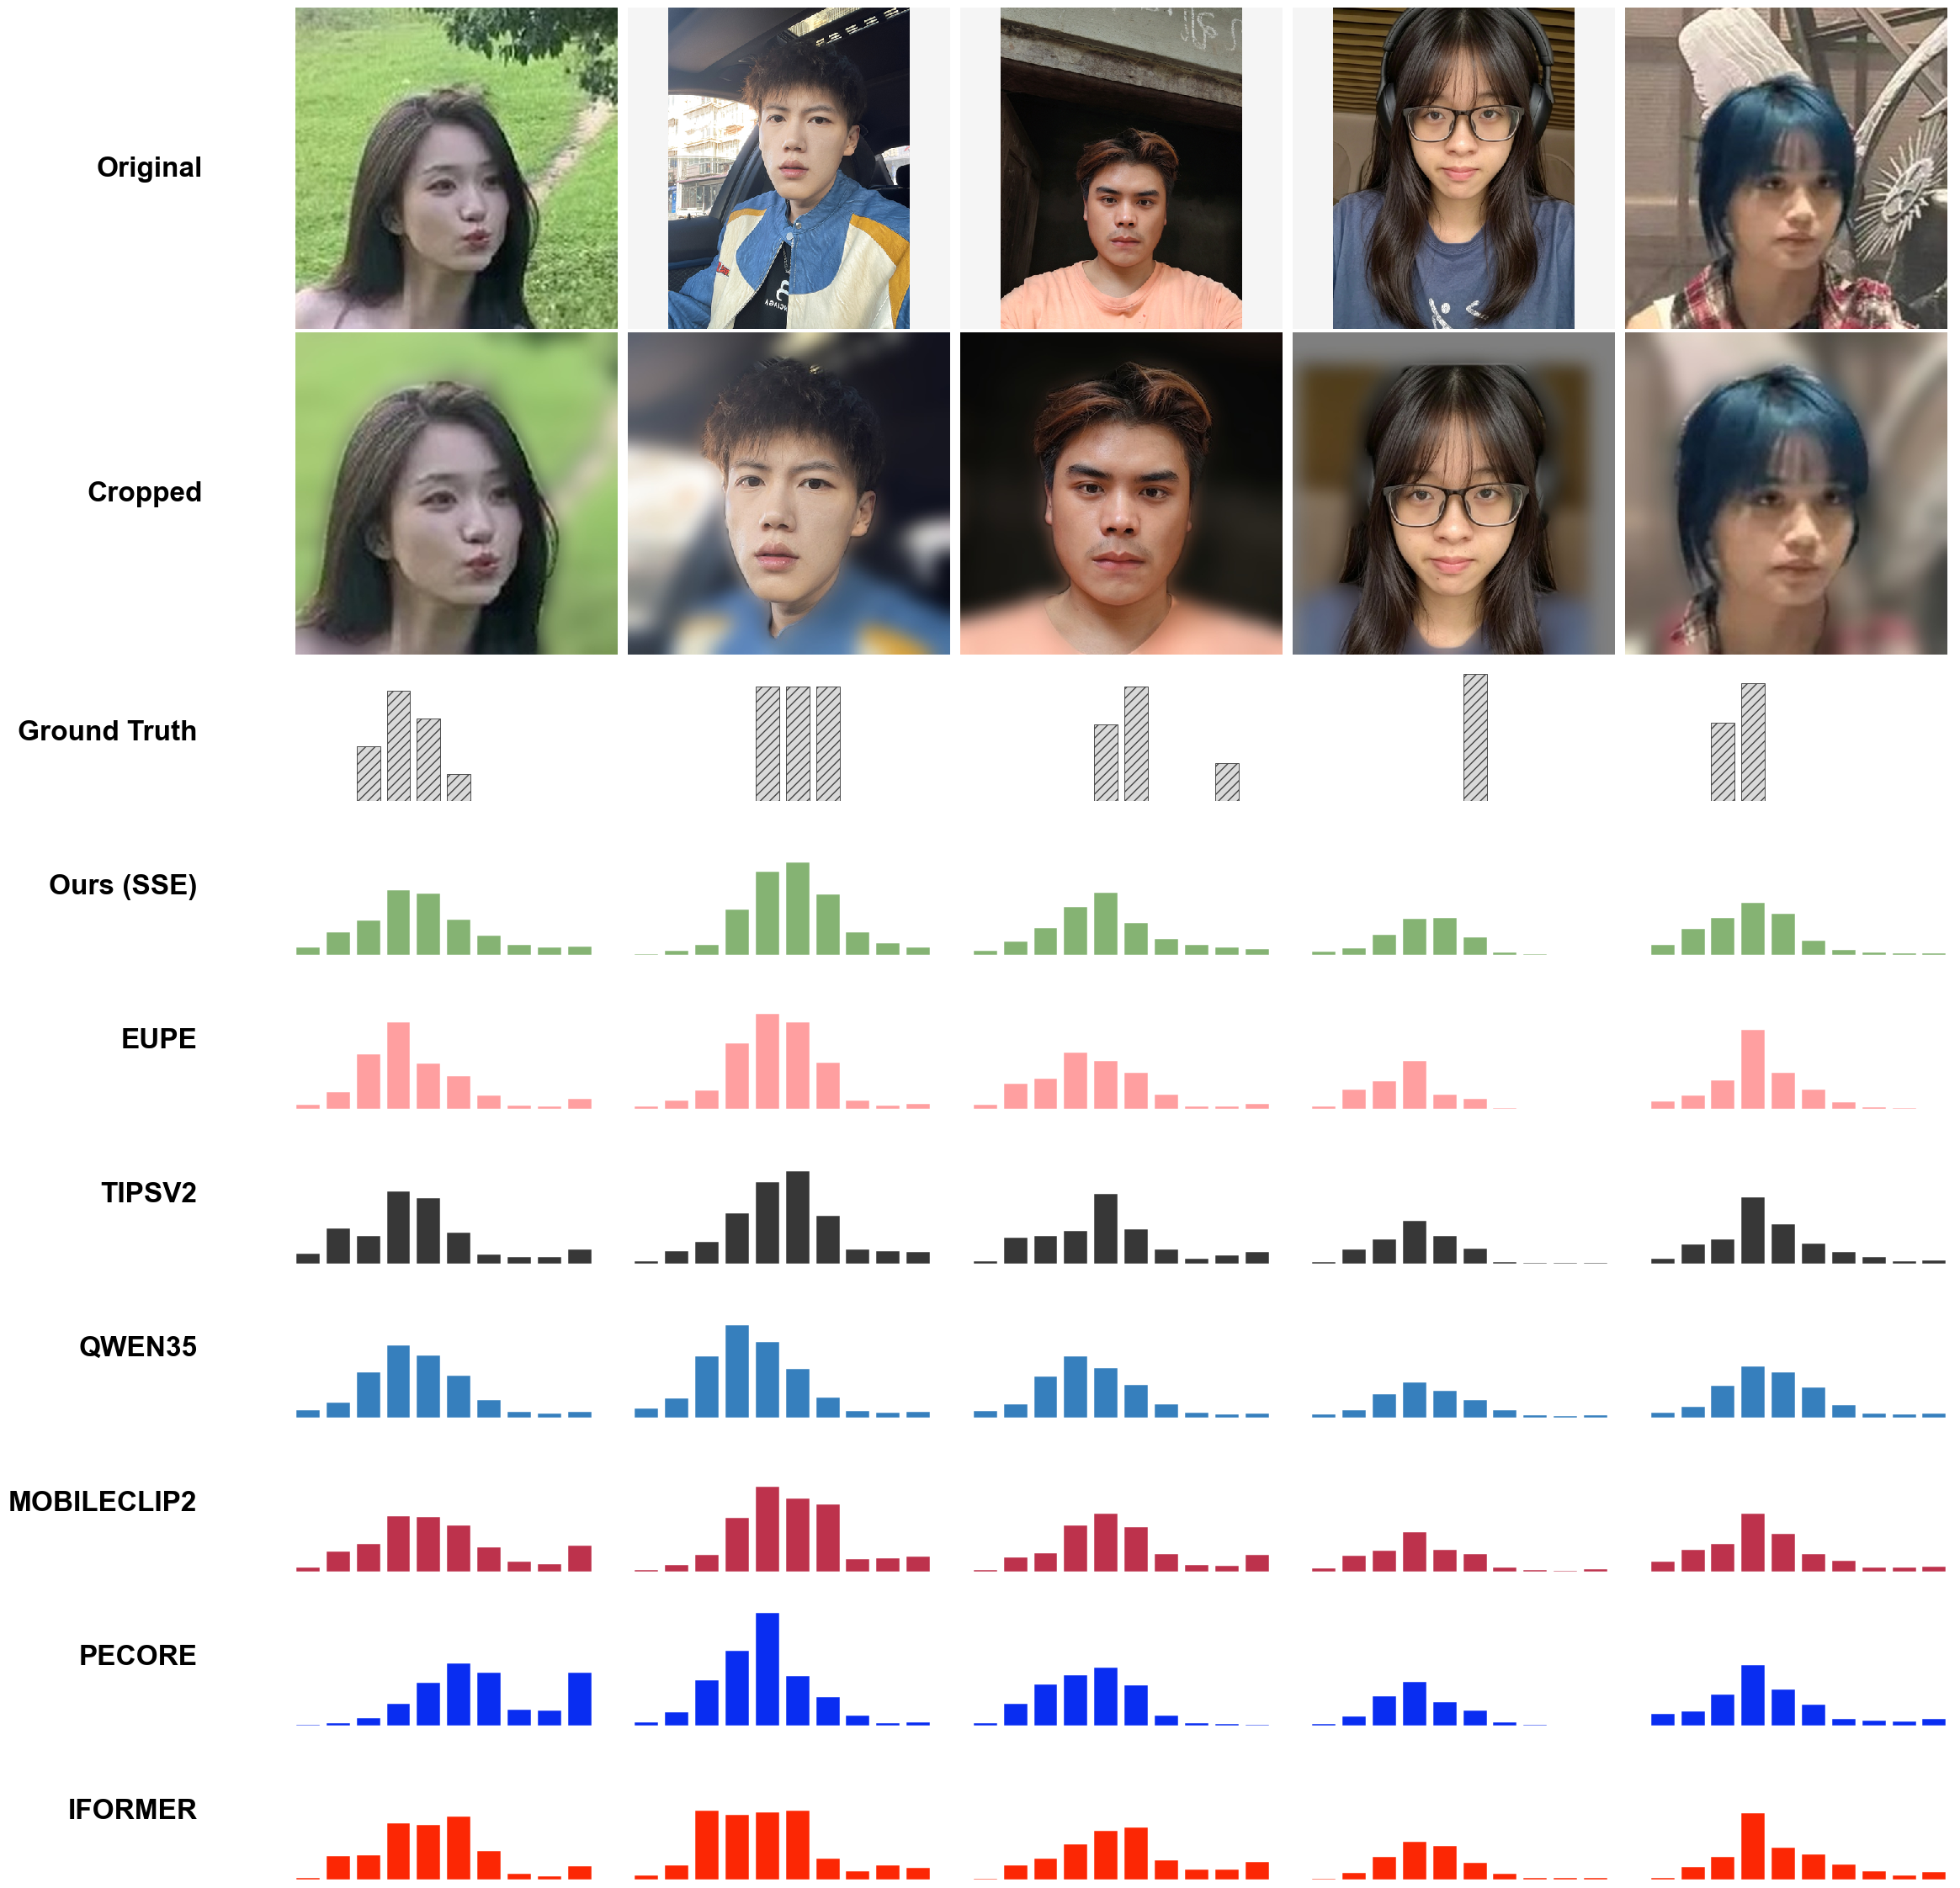

图像已保存到: D:\MyJupyter\Works\FaceScore\outputs\figures\test_distribution_comparison.pdf
图片编号: 3821, 2919, 2922, 2963, 3767
模型预测: 5个训练种子概率均值


In [36]:

from pathlib import Path
from PIL import Image,ImageOps
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
RAW_TEST_DIR=ROOT_DIR/'data'/'test_data'
CROPPED_TEST_DIR=ROOT_DIR/'data'/'test_face_data'
FIGURE_DIR=ROOT_DIR/'outputs'/'figures'
IMAGE_IDS=['3821','2919','2922','2963','3767']
PLOT_MODE='mean'
DISPLAY_SEED=42
FIGURE_WIDTH=22
FIGURE_HEIGHT=25
LEFT_MARGIN=0.1
RIGHT_MARGIN=0.998
TOP_MARGIN=0.955
BOTTOM_MARGIN=0.065
IMAGE_WSPACE=0.0
IMAGE_HSPACE=0.01
PLOT_WSPACE=0.1
PLOT_HSPACE=0.12
BLOCK_HSPACE=0.01
IMAGE_BLOCK_RATIO=2.5
PLOT_BLOCK_RATIO=4.7
IMAGE_DISPLAY_SIZE=512
IMAGE_PAD_COLOR='#F5F5F5'
SUPTITLE_SIZE=26
IMAGE_TITLE_SIZE=18
ROW_LABEL_SIZE=24
ROW_LABEL_X_OFFSET=0.05
AXIS_LABEL_SIZE=14
TICK_SIZE=18
MEAN_SIZE=15
BAR_WIDTH=0.78
SAVE_DPI=800
SAVE_NAME='test_distribution_comparison.pdf'
SHOW_MEAN=True
METHODS_TO_PLOT=['ours','EUPE','TIPSV2','QWEN35','MOBILECLIP2','PECORE','IFORMER']
PALETTE=['#85B373','#FF9FA0','#373737','#367FBD','#BD324C','#092DF1','#FC2704']
COLORS=dict(zip(METHODS_TO_PLOT,PALETTE))
DISPLAY_NAMES={'ours':'Ours (SSE)','EUPE':'EUPE','TIPSV2':'TIPSV2','QWEN35':'QWEN35','MOBILECLIP2':'MOBILECLIP2','PECORE':'PECORE','IFORMER':'IFORMER'}
if len(IMAGE_IDS)!=5 or len({str(item).casefold() for item in IMAGE_IDS})!=5:
    raise ValueError('IMAGE_IDS必须包含5个不同的图片编号')
if PLOT_MODE not in ('mean','seed'):
    raise ValueError("PLOT_MODE必须是'mean'或'seed'")
if PLOT_MODE=='seed' and DISPLAY_SEED not in SEEDS:
    raise ValueError(f'DISPLAY_SEED必须在{SEEDS}中')
if not RAW_TEST_DIR.is_dir() or not CROPPED_TEST_DIR.is_dir():
    raise FileNotFoundError(f'缺少原图或裁剪图目录: {RAW_TEST_DIR} | {CROPPED_TEST_DIR}')
image_paths=[Path(path) for path in test_dataset.image_paths]
if any(path.parent.resolve()!=CROPPED_TEST_DIR.resolve() for path in image_paths):
    raise RuntimeError('当前test_dataset不是从test_face_data加载的，请先核对测试图片与预测顺序，不要混用原图推理结果')
if len(image_paths)!=len(test_targets):
    raise RuntimeError('test_dataset图片数与test_targets不一致')
image_lookup={path.stem.casefold():i for i,path in enumerate(image_paths)}
if len(image_lookup)!=len(image_paths):
    raise RuntimeError('裁剪测试集存在同编号不同扩展名的照片')
original_lookup={path.stem.casefold():path for path in RAW_TEST_DIR.iterdir() if path.suffix.lower() in ('.jpg','.jpeg','.png')}
selected_indices=[]
original_paths=[]
for item in IMAGE_IDS:
    image_id=Path(str(item)).stem.casefold()
    if image_id not in image_lookup:
        raise FileNotFoundError(f'裁剪测试集未找到编号: {item}')
    if image_id not in original_lookup:
        raise FileNotFoundError(f'原始测试集未找到编号: {item}')
    selected_indices.append(image_lookup[image_id])
    original_paths.append(original_lookup[image_id])
predictions_display={}
for method in METHODS_TO_PLOT:
    if method not in all_predictions:
        raise KeyError(f'all_predictions中没有{method}')
    values=np.asarray(all_predictions[method],dtype=np.float64)
    if values.shape!=(len(SEEDS),len(image_paths),10):
        raise RuntimeError(f'{method}的预测形状不正确: {values.shape}')
    predictions_display[method]=values.mean(axis=0) if PLOT_MODE=='mean' else values[SEEDS.index(DISPLAY_SEED)]
plt.rcParams['font.family']='Arial'
plt.rcParams['font.sans-serif']=['Arial']
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['pdf.fonttype']=42
plt.rcParams['ps.fonttype']=42
fig=plt.figure(figsize=(FIGURE_WIDTH,FIGURE_HEIGHT))
outer_grid=fig.add_gridspec(2,1,height_ratios=[IMAGE_BLOCK_RATIO,PLOT_BLOCK_RATIO],hspace=BLOCK_HSPACE)
image_grid=outer_grid[0].subgridspec(2,5,wspace=IMAGE_WSPACE,hspace=IMAGE_HSPACE)
plot_grid=outer_grid[1].subgridspec(8,5,wspace=PLOT_WSPACE,hspace=PLOT_HSPACE)
image_axes=[[fig.add_subplot(image_grid[row,col]) for col in range(5)] for row in range(2)]
plot_axes=[[fig.add_subplot(plot_grid[row,col]) for col in range(5)] for row in range(8)]
fig.subplots_adjust(left=LEFT_MARGIN,right=RIGHT_MARGIN,top=TOP_MARGIN,bottom=BOTTOM_MARGIN)
resample=Image.Resampling.LANCZOS if hasattr(Image,'Resampling') else Image.LANCZOS
score_bins=np.arange(1,11,dtype=np.float64)
for col,index in enumerate(selected_indices):
    cropped_path=image_paths[index]
    for image_row,image_path in enumerate((original_paths[col],cropped_path)):
        with Image.open(image_path) as source:
            rgb=ImageOps.exif_transpose(source).convert('RGB')
            display_image=ImageOps.pad(rgb,(IMAGE_DISPLAY_SIZE,IMAGE_DISPLAY_SIZE),method=resample,color=IMAGE_PAD_COLOR)
        ax=image_axes[image_row][col]
        ax.imshow(display_image,interpolation='nearest')
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    target=np.asarray(test_targets[index],dtype=np.float64)
    if target.shape!=(10,) or not np.isfinite(target).all() or not np.isclose(target.sum(),1.0,atol=1e-5):
        raise RuntimeError(f'{cropped_path.name}的标签分布无效')
    distributions=[target]+[predictions_display[method][index] for method in METHODS_TO_PLOT]
    ymax=min(1.08,max(0.25,np.ceil(max(float(np.max(p)) for p in distributions)*11.0)/10.0))
    label_path=cropped_path.with_suffix('.txt')
    n_ratings=len(test_dataset._read_scores(label_path))
    for plot_row,distribution in enumerate(distributions):
        ax=plot_axes[plot_row][col]
        is_gt=plot_row==0
        color='#D9D9D9' if is_gt else PALETTE[plot_row-1]
        ax.bar(score_bins,distribution,width=BAR_WIDTH,color=color,edgecolor='#444444' if is_gt else 'white',linewidth=0.65 if is_gt else 0.35,hatch='///' if is_gt else None,zorder=3)
        ax.set_xlim(0.4,10.6)
        ax.set_ylim(0,ymax)
        ax.axis('off')
row_names=['Original','Cropped','Ground Truth']+[DISPLAY_NAMES[method] for method in METHODS_TO_PLOT]
all_axes=image_axes+plot_axes
for row,row_name in enumerate(row_names):
    position=all_axes[row][0].get_position()
    fig.text(position.x0-ROW_LABEL_X_OFFSET,(position.y0+position.y1)/2,row_name,fontsize=ROW_LABEL_SIZE,fontfamily='Arial',ha='right',va='center',fontweight='bold')
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
figure_path=FIGURE_DIR/SAVE_NAME
fig.savefig(figure_path,dpi=SAVE_DPI,bbox_inches='tight',facecolor='white')
plt.show()
plt.close(fig)
print(f'图像已保存到: {figure_path}')
print('图片编号: '+', '.join(image_paths[i].stem for i in selected_indices))
print('模型预测: 5个训练种子概率均值' if PLOT_MODE=='mean' else f'模型预测: 随机种子{DISPLAY_SEED}')
